# 00 - Vue d'ensemble : la chaine complete, d'un dossier d'images a un modele en production

Ce notebook deroule UNE fois, en version courte, tout ce que font les autres : c'est la carte.
Chaque etape renvoie au notebook qui la detaille.

```
dossier d'images -> catalogue -> decoupage train / val / test -> pretraitement OpenCV
  -> tenseur normalise -> resnet18 pre-entraine (transfer learning) -> entrainement
  -> evaluation sur le test (une seule fois) -> export ONNX verifie + carte du modele
  -> prediction sans PyTorch (numpy + OpenCV + onnxruntime)
```

- Donnees : NEU-CLS (1 800 images 200 x 200 de defauts de bande d'acier laminee a chaud, 6 classes),
  `python tools/get_data/get_neu_cls.py`.
- Prerequis : le socle de la toolbox (`pip install -e .`), pour `vtb.viz` (affichage) et la
  derniere cellule de controle.
- Duree en mode QUICK sur un CPU 2 coeurs : 3 a 4 minutes.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 4 Decouper -> 2 Importer et explorer -> 5 Pretraiter
  -> 6 Augmenter -> 7 Charger par lots -> 8 Modele -> 9 Perte et optimiseur -> 10 Entrainer
  -> 11 Evaluer -> 12 Sauvegarder et exporter -> 13 Predire
```

Les 13 etapes y sont toutes, en version courte. L'etape 2 se reduit ici a regarder les images,
une fois le catalogue construit et decoupe.

## Etape 1 - Imports et reglages

Tout ce qu'on change pour ses propres donnees est ici, et seulement ici.

In [1]:
import json  # json : lire et ecrire du texte JSON (ici la carte du modele)
import platform  # platform : infos sur la machine (version de Python notee dans la carte)
import random  # random : tirages au hasard de Python (sa graine est fixee plus bas)
import time  # time : chronometre pour mesurer la duree de l'entrainement
from datetime import UTC, datetime  # datetime : date et heure ; UTC = heure universelle, la meme partout
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele ONNX (format standard de modele, lisible sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici le catalogue des images
import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres, sur CPU ou GPU) et apprentissage
import torch.nn as nn  # nn : briques des reseaux de neurones (couches, fonctions de perte)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.metrics import f1_score  # f1_score : score F1, compromis entre precision et rappel
from sklearn.model_selection import train_test_split  # train_test_split : coupe une liste en deux parties tirees au hasard
from torch.utils.data import DataLoader, Dataset  # Dataset : sait lire UN exemple ; DataLoader : les regroupe en lots (batchs)
from torchvision import models  # models : reseaux connus (resnet...) avec leurs poids pre-entraines
from torchvision.transforms import v2  # v2 : transformations d'images de torchvision (ici les augmentations)

from vtb import viz  # viz : affichage de la toolbox (grilles d'images, courbes, matrice de confusion)

QUICK = True  # True : verification rapide sur CPU ; False : reglages de la recette (resnet18_partial.yaml)
DATA_DIR = Path("data/raw/neu_cls_flat")  # un sous-dossier par classe : DATA_DIR/<classe>/<image>
EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichier acceptees comme images (comparees en minuscules)
IMAGE_SIZE = 96 if QUICK else 128  # cote du carre (pixels) donne au reseau : plus petit = plus rapide ; la recette travaille a 128 px
EPOCHS = 3 if QUICK else 10  # une epoque = un passage complet sur toutes les images d'entrainement
PATIENCE = 4  # arret anticipe (early stopping) : stop apres 4 epoques sans baisse de la perte de validation
BATCH_SIZE = 32  # 32 images traitees ensemble a chaque pas (un lot) : plus grand = plus rapide mais plus de memoire
LR = 1e-3  # taux d'apprentissage (taille des pas de correction) de la tete neuve ; le bloc degele apprend 10x moins vite
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # 15 % des images pour la validation, 15 % pour le test, le reste (70 %) pour l'entrainement
SEED = 42  # graine du hasard : memes tirages a chaque execution, donc resultats reproductibles
# calcul sur la carte graphique (cuda) si elle existe, sinon sur le processeur (cpu)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/00_vue_ensemble")  # dossier ou ce notebook ecrit ses resultats (decoupage, poids, export)
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) ; exist_ok : pas d'erreur s'il existe deja

viz.setup_notebook(dpi=80, fmt="jpeg")  # reglage des figures : 80 points par pouce, format jpeg (notebook plus leger)
random.seed(SEED)  # fixe la graine du hasard de Python
np.random.seed(SEED)  # fixe la graine du hasard de numpy
torch.manual_seed(SEED)  # fixe la graine de PyTorch (poids initiaux, ordre des lots, augmentations)
print("device :", DEVICE, "| image", IMAGE_SIZE, "px |", EPOCHS, "epoques")  # rappel des reglages en cours

device : cpu | image 96 px | 3 epoques


## Etape 3 - Cataloguer : une ligne par image

Quel que soit le rangement sur le disque, la suite ne lit les images que par ce tableau
(`path`, `label`). Tri des chemins : l'ordre du disque differe entre Windows et Linux, et le
decoupage en depend. Detail des autres rangements (CSV, MVTec, image + masque) : notebook 01.

In [2]:
rows = [  # liste de dictionnaires {chemin, etiquette}, un par image, construite en une expression
    {"path": str(path), "label": class_dir.name}  # chaque element : le chemin en texte et la classe = nom du sous-dossier
    # pour chaque sous-dossier de DATA_DIR (une classe), dans l'ordre alphabetique
    for class_dir in sorted(d for d in DATA_DIR.iterdir() if d.is_dir())
    # pour chaque fichier image du sous-dossier (rglob : sous-dossiers compris), tries
    for path in sorted(p for p in class_dir.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS)
]
catalog = pd.DataFrame(rows)  # le catalogue : tableau pandas, une ligne par image, colonnes path et label
class_names = sorted(catalog["label"].unique())  # classes triees ; la position dans cette liste = numero de classe pour le reseau
print(len(catalog), "images,", len(class_names), "classes")  # nombre d'images et de classes
print(catalog["label"].value_counts().sort_index().to_dict())  # nombre d'images par classe : verifie l'equilibre entre classes

1800 images, 6 classes
{'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted': 300, 'rolled': 300, 'scratches': 300}


## Etape 4 - Decouper : le decoupage train / val / test

Stratifie (memes proportions de classes partout) et fige par la graine : on preleve d'abord le
test, puis la validation dans le reste. Le test ne sert qu'une fois, a la fin ; la validation
choisit l'epoque et les seuils. Le decoupage est enregistre (`split.csv`) pour que toutes les
experiences soient comparables. Groupes (piece, bobine) et decoupage temporel : notebook 01.

In [3]:
catalog["split"] = "train"  # nouvelle colonne split : tout le monde en train au depart
# tire 15 % des lignes pour le test ; stratify : memes proportions de classes ; on ne garde que les indices
_, test_idx = train_test_split(catalog.index, test_size=TEST_FRACTION, stratify=catalog["label"], random_state=SEED)
catalog.loc[test_idx, "split"] = "test"  # ces lignes passent en test
rest = catalog[catalog["split"] == "train"]  # les images restantes (encore en train)
# tire la validation dans le reste : 0,15 / 0,85 du reste = 15 % du total
_, val_idx = train_test_split(rest.index, test_size=VAL_FRACTION / (1 - TEST_FRACTION), stratify=rest["label"], random_state=SEED)
catalog.loc[val_idx, "split"] = "val"  # ces lignes passent en validation
catalog.to_csv(OUT / "split.csv", index=False)  # enregistre le decoupage : toutes les experiences utiliseront le meme
# tableau croise classes x parties, avec totaux (margins) : controle de la stratification
print(pd.crosstab(catalog["label"], catalog["split"], margins=True))

split      test  train  val   All
label                            
crazing      45    210   45   300
inclusion    45    210   45   300
patches      45    210   45   300
pitted       45    210   45   300
rolled       45    210   45   300
scratches    45    210   45   300
All         270   1260  270  1800


## Etape 2 - Importer et explorer : regarder les images avant tout calcul

Six images par classe : on verifie que les etiquettes ont un sens et on repere ce qui pourrait
servir de raccourci au modele (bordure, horodatage, luminosite differente par classe).

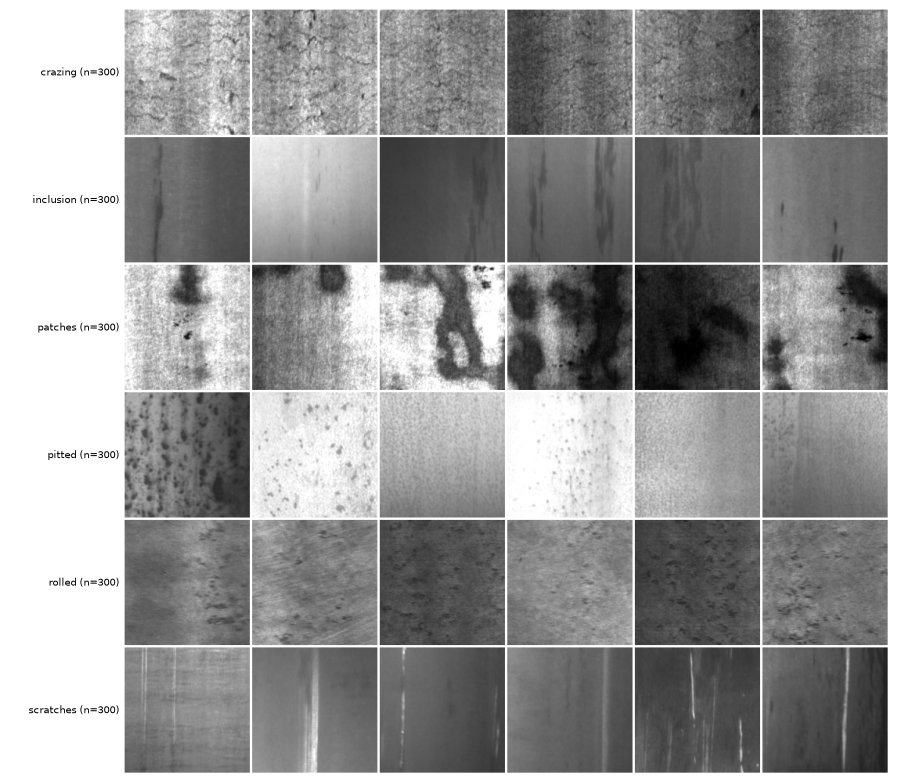

In [4]:
# montage de 6 images par classe pour un controle a l'oeil
viz.class_montage(catalog["path"].tolist(), catalog["label"].tolist(), per_class=6)

## Etapes 5 a 7 - Pretraiter, augmenter, charger par lots : pretraitement et tenseur

Ordre fixe, le meme a l'entrainement, en prediction et dans le programme de production :

lecture (RGB) -> pretraitement OpenCV (ici un simple redimensionnement) -> float [0, 1] (C, H, W)
-> augmentation (train seulement) -> normalisation (moyenne / ecart-type d'ImageNet, imposes par
les poids pre-entraines).

- Lecture par `np.fromfile` + `cv2.imdecode` : `cv2.imread` echoue en silence sur un chemin
  Windows avec accents.
- Les images NEU sont grises : on recopie le canal 3 fois, car le reseau a ete entraine en RGB.
- `INTER_AREA` pour reduire : la seule interpolation qui ne cree pas de moirage sur une texture fine.

lot : (32, 3, 96, 96) torch.float32 | moyenne 0.435


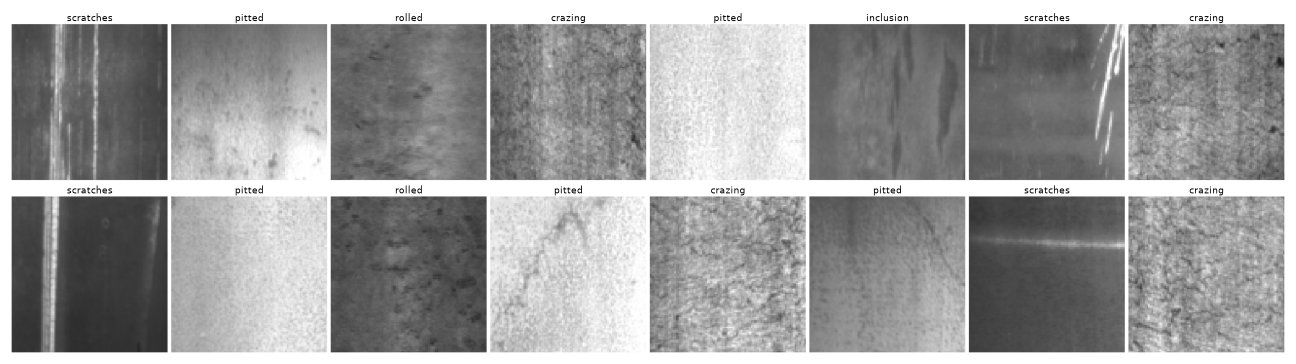

In [5]:
# moyenne et ecart-type de chaque canal (R, G, B) sur ImageNet, imposes par les poids pre-entraines
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def read_image(path, color="rgb"):  # lit un fichier image ; renvoie un tableau numpy RGB (H, W, 3), ou gris (H, W) si color="gray"
    """Fichier -> numpy (H, W, 3) RGB ou (H, W) gris, uint8 ou uint16 conserve."""
    # np.fromfile lit les octets (marche avec les accents) ; imdecode les decode tels quels (IMREAD_UNCHANGED)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si l'image a 4 canaux (couleur + transparence alpha)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "gray":  # si on demande du gris
        # couleur -> gris si besoin (OpenCV range les couleurs en BGR) ; sinon l'image est deja grise
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    # gris : canal recopie 3 fois (le reseau attend 3 canaux) ; couleur : BGR d'OpenCV -> RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize(image, size):  # redimensionne l'image en carre size x size ; renvoie la nouvelle image
    """Operation `resize` de la toolbox (interpolation auto : area pour reduire, linear pour agrandir)."""
    shrinking = size * size < image.shape[0] * image.shape[1]  # True si la nouvelle image a moins de pixels que l'ancienne (on reduit)
    # INTER_AREA (moyenne de zone) pour reduire sans moirage ; INTER_LINEAR (lineaire) pour agrandir
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)


def preprocess(image):  # pretraitement OpenCV de ce notebook : seulement le redimensionnement ; renvoie l'image
    return resize(image, IMAGE_SIZE)  # redimensionne a IMAGE_SIZE x IMAGE_SIZE


def to_tensor(image):  # image numpy -> tenseur PyTorch float32 (canaux, hauteur, largeur) dans [0, 1]
    """uint8 / uint16 (H, W, C) -> float32 (C, H, W) dans [0, 1]."""
    peak = 65535.0 if image.dtype == np.uint16 else 255.0  # valeur maximale possible : 65535 pour une image 16 bits, 255 pour 8 bits
    array = image.astype(np.float32) / peak  # nombres a virgule (float32) entre 0 et 1
    # gris : ajoute un axe canal devant (1, H, W) ; couleur : (H, W, C) -> (C, H, W), l'ordre de PyTorch
    array = array[None] if array.ndim == 2 else array.transpose(2, 0, 1)
    # rend le tableau contigu en memoire (transpose ne deplace rien) puis le convertit en tenseur sans copie
    return torch.from_numpy(np.ascontiguousarray(array))


def normalize(tensor):  # normalisation : retire la moyenne puis divise par l'ecart-type, canal par canal ; renvoie le tenseur
    # moyenne en forme (3, 1, 1) : s'applique a tous les pixels de chaque canal (broadcast)
    mean = torch.tensor(IMAGENET_MEAN).view(-1, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(-1, 1, 1)  # ecart-type, meme forme
    return (tensor - mean) / std  # valeurs centrees autour de 0, comme celles vues par le reseau pendant son pre-entrainement


class ImageDataset(Dataset):  # jeu de donnees PyTorch : donne l'image numero i prete pour le reseau
    """Lit, pretraite, augmente (si demande), normalise ; renvoie (tenseur, indice de classe)."""

    def __init__(self, frame, augment=None):  # constructeur : recoit un morceau du catalogue et une augmentation (ou None)
        self.paths = frame["path"].tolist()  # liste des chemins des images
        # numero de classe de chaque image (position de son etiquette dans class_names)
        self.targets = [class_names.index(label) for label in frame["label"]]
        self.augment = augment  # augmentation a appliquer (None = aucune, pour val et test)

    def __len__(self):  # nombre d'images : le DataLoader en a besoin pour former ses lots
        return len(self.paths)  # une image par chemin

    def __getitem__(self, index):  # renvoie l'exemple numero index : (tenseur normalise, numero de classe)
        tensor = to_tensor(preprocess(read_image(self.paths[index])))  # lecture -> pretraitement -> tenseur [0, 1], toujours dans cet ordre
        if self.augment is not None:  # si une augmentation est prevue (train seulement)
            tensor = self.augment(tensor)  # transformation au hasard de l'image (ici des retournements)
        return normalize(tensor), self.targets[index]  # normalisation en dernier, puis la classe attendue


# Une augmentation est une hypothese : "l'etiquette ne change pas si on retourne l'image" (vrai
# pour ces defauts). Detail et presets : notebook 03.
# Compose enchaine les deux retournements (gauche-droite, haut-bas), chacun applique 1 fois sur 2
augment = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomVerticalFlip()])
# un sous-tableau par partie (train, val, test), renumerote a partir de 0
frames = {name: catalog[catalog["split"] == name].reset_index(drop=True) for name in ("train", "val", "test")}
generator = torch.Generator().manual_seed(SEED)  # generateur de hasard a graine fixe : meme ordre de melange a chaque execution
# lots de 32 melanges (shuffle) a chaque epoque ; drop_last : le dernier lot incomplet est jete
train_loader = DataLoader(ImageDataset(frames["train"], augment), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=generator)
val_loader = DataLoader(ImageDataset(frames["val"]), batch_size=BATCH_SIZE)  # lots de validation, sans melange ni augmentation
test_loader = DataLoader(ImageDataset(frames["test"]), batch_size=BATCH_SIZE)  # lots de test, idem

images, targets = next(iter(train_loader))  # premier lot pour controle : images (lot, canaux, H, W) et classes
# forme, type et moyenne du lot (proche de 0 apres normalisation)
print("lot :", tuple(images.shape), images.dtype, "| moyenne", round(float(images.mean()), 3))
# 16 premieres images ; mean / std servent a annuler la normalisation pour l'affichage
viz.show_batch(images[:16], targets[:16].tolist(), class_names, mean=IMAGENET_MEAN, std=IMAGENET_STD, ncols=8)

## Etapes 8 et 9 - Modele, perte et optimiseur : resnet18 pre-entraine sur ImageNet, strategie "partial"

On remplace la derniere couche (1 000 classes ImageNet) par une couche a 6 sorties, on gele
tout, puis on degele la tete et le dernier bloc (`layer4`). Deux regles :

- l'optimiseur ne recoit que ce qui apprend ;
- ce qui etait deja appris apprend plus lentement (taux x 0,1) que la tete neuve, sinon les
  premiers gradients, bruites, detruisent les poids pre-entraines.

Choix du modele et les cinq strategies comparees : notebook 06.

In [6]:
# resnet18 avec les poids appris sur ImageNet : le transfer learning part de ce savoir deja acquis
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# nouvelle derniere couche (la tete) : autant de sorties que de classes (6) au lieu de 1 000
model.fc = nn.Linear(model.fc.in_features, len(class_names))
for param in model.parameters():  # pour chaque poids du reseau
    param.requires_grad = False  # gele : ce poids ne sera plus modifie (pas de gradient calcule)
for param in [*model.fc.parameters(), *model.layer4.parameters()]:  # pour chaque poids de la tete et du dernier bloc (layer4)
    param.requires_grad = True  # degele : ces poids apprendront
model.to(DEVICE)  # envoie le modele sur le GPU ou le CPU choisi

param_groups = [  # deux groupes de poids, chacun avec son propre taux d'apprentissage
    {"params": list(model.fc.parameters()), "lr": LR},  # la tete neuve apprend au taux LR
    # le bloc pre-entraine apprend 10 fois moins vite pour ne pas perdre ce qu'il sait
    {"params": list(model.layer4.parameters()), "lr": LR * 0.1},
]
# optimiseur AdamW : corrige les poids a partir des gradients ; weight_decay freine les poids trop grands
optimizer = torch.optim.AdamW(param_groups, weight_decay=1e-4)
# divise le taux par 2 si la perte de validation ne baisse plus pendant 2 epoques
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss()  # fonction de perte (mesure de l'erreur) de la classification : entropie croisee
# compte les poids qui vont apprendre (numel = nombre de valeurs d'un tenseur)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parametres entraines : {trainable:,} sur {sum(p.numel() for p in model.parameters()):,}")  # poids entraines / poids totaux


def freeze_frozen_batchnorm(net):  # remet en mode evaluation les BatchNorm (couches qui normalisent par lot) dont tous les poids sont geles
    """Une BatchNorm gelee suit quand meme les statistiques en mode train : on la remet en eval."""
    for module in net.modules():  # pour chaque couche du reseau, blocs internes compris
        # si c'est une BatchNorm et qu'aucun de ses poids n'apprend
        if isinstance(module, nn.BatchNorm2d) and not any(p.requires_grad for p in module.parameters()):
            module.eval()  # mode evaluation : ses moyennes memorisees ne bougent plus

parametres entraines : 8,396,806 sur 11,179,590


## Etape 10 - Entrainer

Les cinq lignes (zero_grad, forward, perte, backward, step) dans une boucle par epoque. On
garde le modele de la meilleure perte de VALIDATION et on s'arrete apres `PATIENCE` epoques
sans progres. La courbe se met a jour pendant l'entrainement.

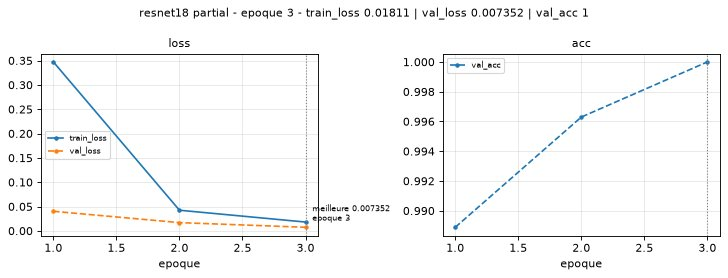

entrainement : 29 s | meilleure perte de validation 0.0074


In [7]:
def train_one_epoch(net, loader):  # fait une epoque d'entrainement ; renvoie (perte moyenne, exactitude) sur le train
    net.train()  # mode entrainement (comportements propres a l'apprentissage, ex. BatchNorm)
    freeze_frozen_batchnorm(net)  # mais les BatchNorm gelees restent en mode evaluation
    total, correct, seen = 0.0, 0, 0  # somme des pertes, nombre de bonnes reponses, nombre d'images vues
    for x, y in loader:  # pour chaque lot : x = images, y = classes attendues
        x, y = x.to(DEVICE), y.to(DEVICE)  # envoie le lot sur le meme appareil que le modele
        optimizer.zero_grad(set_to_none=True)  # efface les gradients du pas precedent (sinon ils s'additionnent)
        logits = net(x)  # forward : le reseau donne les logits (un score brut par classe, avant softmax)
        loss = criterion(logits, y)  # perte : ecart entre les scores et les vraies classes
        loss.backward()  # backward : calcule le gradient (sens de correction de chaque poids pour baisser la perte)
        optimizer.step()  # l'optimiseur corrige les poids d'un petit pas dans ce sens
        total += loss.item() * len(y)  # perte moyenne du lot x taille du lot = somme des pertes ; item() : tenseur -> nombre Python
        correct += (logits.argmax(1) == y).sum().item()  # argmax(1) : classe au plus grand score ; on compte les bonnes reponses
        seen += len(y)  # images vues
    return total / seen, correct / seen  # perte moyenne et exactitude (part de bonnes reponses) de l'epoque


@torch.no_grad()  # decorateur : aucun gradient calcule dans cette fonction (plus rapide, moins de memoire)
def predict_loader(net, loader):  # passe tout un DataLoader dans le reseau ; renvoie perte moyenne, probabilites et vraies classes
    """Perte moyenne, probabilites (N, C) et cibles (N,) sur un DataLoader."""
    net.eval()  # mode evaluation : comportement fixe, sans hasard
    total, probs, ys = 0.0, [], []  # somme des pertes, probabilites par lot, classes par lot
    for x, y in loader:  # pour chaque lot
        logits = net(x.to(DEVICE))  # scores bruts du reseau
        total += criterion(logits, y.to(DEVICE)).item() * len(y)  # ajoute la perte du lot (moyenne x taille du lot)
        probs.append(torch.softmax(logits, 1).cpu())  # softmax : scores -> probabilites (positives, somme 1) ; rapatriees sur CPU
        ys.append(y)  # garde les vraies classes du lot
    y_all = torch.cat(ys).numpy()  # colle les lots bout a bout et convertit en tableau numpy
    return total / len(y_all), torch.cat(probs).numpy(), y_all  # perte moyenne, probabilites (N, C) et classes (N,)


# courbe mise a jour a chaque epoque : pertes train / val et exactitude val
live = viz.LivePlot(metrics=("train_loss", "val_loss", "val_acc"), title="resnet18 partial")
# meilleure perte de validation (infinie au depart), epoques sans progres, heure de depart
best_loss, bad, start = float("inf"), 0, time.time()
for epoch in range(1, EPOCHS + 1):  # pour chaque epoque, numerotee a partir de 1
    train_loss, train_acc = train_one_epoch(model, train_loader)  # une epoque d'apprentissage
    val_loss, val_probs, val_y = predict_loader(model, val_loader)  # mesure sur la validation (sans apprendre)
    val_acc = float((val_probs.argmax(1) == val_y).mean())  # exactitude de validation : part des images bien classees
    scheduler.step(val_loss)  # le planificateur regarde la perte de validation et baisse le taux si elle stagne
    live.update(epoch, train_loss=train_loss, val_loss=val_loss, val_acc=val_acc)  # ajoute les points de l'epoque sur la courbe
    if val_loss < best_loss:  # si la validation s'ameliore
        best_loss, bad = val_loss, 0  # nouveau record, compteur sans progres remis a 0
        torch.save(model.state_dict(), OUT / "best.pt")  # sauvegarde les poids de ce meilleur modele (state_dict = dictionnaire des poids)
    else:  # sinon (pas de progres)
        bad += 1  # une epoque de plus sans progres
        if bad >= PATIENCE:  # trop d'epoques sans progres
            break  # arret anticipe : on sort de la boucle
live.close()  # fige la courbe finale
# recharge les poids du meilleur modele, pas ceux de la derniere epoque ; weights_only : chargement sur
model.load_state_dict(torch.load(OUT / "best.pt", map_location=DEVICE, weights_only=True))
# duree et meilleure perte de validation
print(f"entrainement : {time.time() - start:.0f} s | meilleure perte de validation {best_loss:.4f}")

## Etape 11 - Evaluer : sur le test, une seule fois

Exactitude et F1 macro (moyenne des F1 par classe : honnete quand les classes sont
desequilibrees), matrice de confusion. Evaluation complete (ROC, calibration, erreurs, Grad-CAM) :
notebook 07.

{'n_images': 270, 'accuracy': 0.9888888888888889, 'f1_macro': 0.9888875169774046}


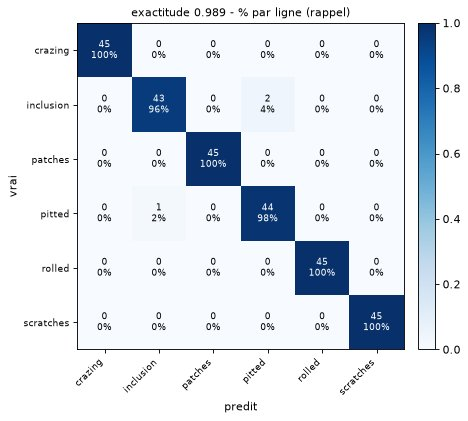

In [8]:
test_loss, test_probs, test_y = predict_loader(model, test_loader)  # predictions sur le test, une seule fois, avec le meilleur modele
test_pred = test_probs.argmax(1)  # classe predite = celle de plus grande probabilite
metrics = {  # mesures finales (elles iront aussi dans la carte du modele)
    "n_images": int(len(test_y)),  # nombre d'images de test
    "accuracy": float((test_pred == test_y).mean()),  # exactitude : part de bonnes reponses
    # F1 macro : moyenne des F1 de chaque classe, honnete si les classes sont desequilibrees
    "f1_macro": float(f1_score(test_y, test_pred, average="macro")),
}
print(metrics)  # affiche les mesures
viz.confusion_matrix(test_y, test_pred, class_names)  # matrice de confusion : lignes = vraies classes, colonnes = classes predites

## Etape 12 - Sauvegarder et exporter : export ONNX, verifie contre PyTorch

Un export qui passe sans verification ne prouve rien : un operateur mal traduit ne leve
aucune erreur, il donne des sorties fausses. On compare donc les sorties sur de VRAIES images,
avec un lot (3) different de celui de l'export (2), ce qui teste aussi le lot dynamique.
Toutes les variantes (lot fige, OpenVINO, latence) : notebook 17.

In [9]:
EXPORT = OUT / "export"  # sous-dossier de l'export
EXPORT.mkdir(exist_ok=True)  # cree le dossier s'il n'existe pas
model_cpu = model.cpu().eval()  # modele sur CPU et en mode evaluation, l'etat attendu pour l'export
# entree d'exemple (2 images de zeros) : l'exporteur suit le calcul sur elle pour ecrire le graphe
example = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.onnx.export(  # ecrit le reseau au format ONNX : le calcul decrit dans un fichier, executable sans PyTorch
    model_cpu,  # le modele a exporter
    (example,),  # les arguments de forward, sous forme de tuple
    str(EXPORT / "model.onnx"),  # fichier de sortie
    input_names=["input"],  # nom de l'entree dans le fichier ONNX (repris par le programme de production)
    output_names=["logits"],  # nom de la sortie
    dynamic_shapes={"x": {0: torch.export.Dim("batch", min=1, max=1024)}},  # x : nom de l'argument de forward ; lot dynamique
    opset_version=18,  # version du jeu d'operateurs ONNX (doit etre connue du moteur qui lira le fichier)
    dynamo=True,  # l'exporteur torch.export (le defaut depuis PyTorch 2.9)
    external_data=False,  # poids dans le meme fichier .onnx
)
# 3 vraies images de validation, pretraitees et normalisees, empilees en un lot
real = torch.stack([ImageDataset(frames["val"].head(3))[i][0] for i in range(3)])
# charge le fichier ONNX dans onnxruntime, execution sur CPU
session = ort.InferenceSession(str(EXPORT / "model.onnx"), providers=["CPUExecutionProvider"])
with torch.no_grad():  # sans calcul de gradient
    torch_out = model_cpu(real).numpy()  # sorties de PyTorch sur ces 3 images, converties en numpy
onnx_out = session.run(None, {"input": real.numpy()})[0]  # sorties d'onnxruntime sur les memes images ; [0] = premiere (et seule) sortie
# plus grand ecart entre les deux sorties, et plus grande valeur absolue des logits
diff, scale = float(np.abs(torch_out - onnx_out).max()), float(np.abs(torch_out).max())
# erreur si l'ecart depasse une petite tolerance (absolue + relative a la taille des valeurs)
assert diff <= 1e-4 + 1e-3 * scale, f"ONNX different de PyTorch : ecart {diff:.2e}"
print(f"verification ONNX OK : ecart max {diff:.1e} pour des logits jusqu'a {scale:.1f}")  # affiche le resultat du controle

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


verification ONNX OK : ecart max 4.6e-06 pour des logits jusqu'a 10.5


## Etape 12 - Sauvegarder et exporter : la carte du modele, le contrat avec le programme de production

Un programme C# ou Python qui charge `model.onnx` n'a besoin que de cette carte : couleur de
lecture, pretraitement dans l'ordre, taille, mise a l'echelle, normalisation, sorties, classes.
Meme format que l'export de la production (`vtb.export.card`).

In [10]:
card = {  # la carte du modele : tout ce qu'un programme doit savoir pour utiliser model.onnx
    "task": "classification",  # type de tache
    "model_name": "resnet18",  # architecture du reseau
    "created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),  # date de creation en heure universelle, format ISO
    # versions des outils (pour reproduire ou diagnostiquer)
    "framework": {"python": platform.python_version(), "torch": torch.__version__, "onnxruntime": ort.__version__},
    "input": {  # description exacte de l'entree attendue
        "name": "input",  # nom de l'entree dans le fichier ONNX
        "layout": "NCHW",  # ordre des axes : lot (N), canaux (C), hauteur (H), largeur (W)
        "height": IMAGE_SIZE,  # hauteur en pixels
        "width": IMAGE_SIZE,  # largeur en pixels
        "channels": 3,  # 3 canaux
        "color": "RGB",  # ordre des canaux : rouge, vert, bleu
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle vers [0, 1] selon la profondeur de l'image
        "mean": IMAGENET_MEAN,  # moyennes a retirer, canal par canal
        "std": IMAGENET_STD,  # ecarts-types par lesquels diviser
        "resize": "stretch",  # redimensionnement par etirement (proportions non gardees)
        "letterbox_pad_value": None,  # pas de letterbox (bandes ajoutees pour garder les proportions), donc pas de couleur de bande
        "dynamic_batch": True,  # le nombre d'images par appel peut varier
        "read_color": "rgb",  # lire le fichier en RGB
    },
    # pretraitements a appliquer dans l'ordre, avec leurs reglages
    "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],
    # sorties : logits de forme (lot, nombre de classes) ; classe predite = argmax
    "outputs": [{"name": "logits", "shape": ["batch", len(class_names)], "description": "scores avant softmax ; classe = argmax"}],
    "class_names": class_names,  # noms des classes dans l'ordre des sorties
    "thresholds": {},  # pas de seuil de decision particulier ici
    "postprocess": {},  # pas de post-traitement (utile en detection)
    "metrics": metrics,  # scores obtenus sur le test
    "latency_ms": {},  # temps de calcul non mesure ici (voir notebook 17)
    "files": {"onnx": "model.onnx"},  # nom du fichier modele, relatif au dossier de la carte
    "notes": f"notebook 00 ; verification ONNX : ecart max {diff:.2e}",  # remarque libre : provenance et resultat de la verification
}
# ecrit la carte en JSON lisible (indent=2) a cote du modele
(EXPORT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
print(json.dumps(card["input"], indent=1)[:400])  # affiche le debut de la partie input

{
 "name": "input",
 "layout": "NCHW",
 "height": 96,
 "width": 96,
 "channels": 3,
 "color": "RGB",
 "dtype": "float32",
 "scale": "divide by 255 (8 bits) or 65535 (16 bits)",
 "mean": [
  0.485,
  0.456,
  0.406
 ],
 "std": [
  0.229,
  0.224,
  0.225
 ],
 "resize": "stretch",
 "letterbox_pad_value": null,
 "dynamic_batch": true,
 "read_color": "rgb"
}


## Etape 13 - Predire : sans PyTorch (numpy + OpenCV + onnxruntime)

C'est tout ce que fait le programme de production : lire la carte, preparer l'image comme elle
le dit, executer le modele, appliquer un softmax. Si ces quelques lignes rendent les memes
probabilites que PyTorch, le portage C# peut s'ecrire en les lisant. Version complete pour
toutes les taches : notebook 18.

ecart max des probabilites ONNX (sans torch) / PyTorch : 2.7e-08


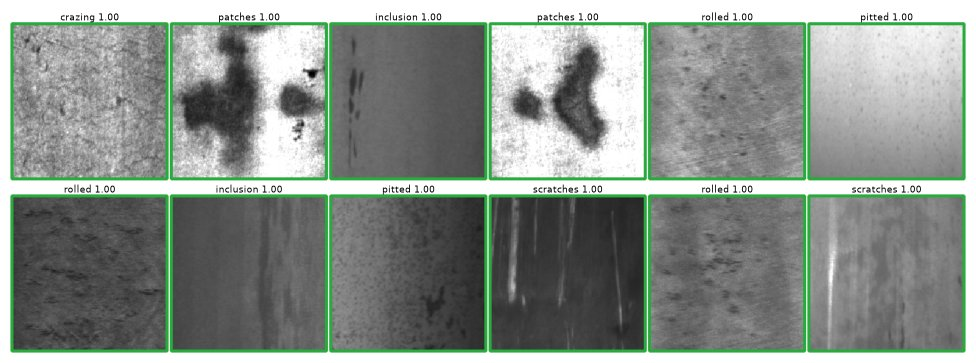

In [11]:
# relit la carte depuis le disque, comme le programme de production
card = json.loads((EXPORT / "model_card.json").read_text(encoding="utf-8"))
# charge le modele indique par la carte
session = ort.InferenceSession(str(EXPORT / card["files"]["onnx"]), providers=["CPUExecutionProvider"])


def predict_file(path):  # predit la classe d'un fichier image sans PyTorch ; renvoie (nom de classe, probabilites)
    spec = card["input"]  # la partie input de la carte
    image = read_image(path, spec["read_color"])  # lecture dans la couleur demandee par la carte
    for step in card["preprocess"]:  # une seule operation ici ; voir le notebook 07 pour une chaine
        assert step["name"] == "resize"  # verifie que l'operation est bien celle qu'on sait faire
        image = resize(image, step["size"])  # redimensionne a la taille indiquee
    # float32 dans [0, 1] selon la profondeur (8 ou 16 bits)
    x = image.astype(np.float32) / (65535.0 if image.dtype == np.uint16 else 255.0)
    # normalisation avec la moyenne et l'ecart-type de la carte
    x = (x - np.array(spec["mean"], np.float32)) / np.array(spec["std"], np.float32)
    # (H, W, C) -> (C, H, W), [None] ajoute l'axe du lot ; [0][0] : premiere sortie, premiere image
    logits = session.run(None, {spec["name"]: x.transpose(2, 0, 1)[None]})[0][0]
    probs = np.exp(logits - logits.max())  # softmax a la main : exponentielle des scores (moins le max, pour eviter un depassement)
    probs /= probs.sum()  # divise par la somme : probabilites qui totalisent 1
    return card["class_names"][int(probs.argmax())], probs  # nom de la classe la plus probable et toutes les probabilites


sample = frames["test"].sample(12, random_state=SEED)  # 12 images de test tirees au hasard (graine fixe)
results = [predict_file(p) for p in sample["path"]]  # prediction sans PyTorch pour chacune
onnx_probs = np.stack([r[1] for r in results])  # probabilites ONNX empilees en tableau (12, classes)
torch_probs = test_probs[sample.index.to_numpy()]  # probabilites PyTorch des memes images (memes positions dans le test)
# ecart max entre les deux : doit etre minuscule
print("ecart max des probabilites ONNX (sans torch) / PyTorch :", f"{np.abs(onnx_probs - torch_probs).max():.1e}")
viz.grid(  # grille d'images avec leur prediction
    [read_image(p) for p in sample["path"]],  # les 12 images
    [f"{label} {probs.max():.2f}" for label, probs in results],  # legende : classe predite et sa probabilite
    ncols=6,  # 6 images par ligne
    # couleur du cadre selon que la prediction est juste (True) ou fausse (False)
    borders=[label == truth for (label, _), truth in zip(results, sample["label"])],
)

## Resultats

En mode QUICK (96 px, 3 epoques) le modele depasse deja 95 % sur le test ; la recette
`resnet18_partial` (128 px, 10 epoques) atteint 100 % sur ce jeu. NEU-CLS est un jeu facile pour un
reseau pre-entraine : sur des images d'usine, le gros du travail est dans les donnees (notebooks
01, 04, 05) et dans le choix du seuil (07).

In [12]:
# tableau recapitulatif d'une ligne : mesures, taille d'image, epoques faites, ecart ONNX
summary = pd.DataFrame([{**metrics, "image_size": IMAGE_SIZE, "epochs_run": epoch, "onnx_max_diff": diff}])
display(summary)  # affiche le tableau

,n_images,accuracy,f1_macro,image_size,epochs_run,onnx_max_diff
0,270,0.988889,0.988888,96,3,0.000005


## Passer en production

La meme experience en mode production : un YAML et une commande.

```yaml
# recipes/classification/configs/resnet18_partial.yaml (extrait)
data: {root: data/raw/neu_cls_flat, layout: class_folders, color: rgb}
split: {file: outputs/classification/split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}
preprocess: [{name: resize, size: 128}]
augment: [{name: hflip}, {name: vflip}]
model: {name: resnet18, pretrained: true, transfer: {strategy: partial, unfreeze_last: 1, backbone_lr_factor: 0.1}}
train: {epochs: 10, batch_size: 32, lr: 0.001, weight_decay: 0.0001, patience: 4, scheduler: plateau}
```

```
python recipes/classification/scripts/run.py --config recipes/classification/configs/resnet18_partial.yaml
python -m vtb.serve --model outputs/notebooks/00_vue_ensemble/export      # le modele du notebook, servi en HTTP
```

Controle : le dossier exporte par ce notebook est relu par le predicteur de production
(`vtb.serve.predictor.OnnxPredictor`, qui valide aussi la carte), et le decoupage est compare a
celui de la recette.

In [13]:
from vtb.serve.predictor import OnnxPredictor  # predicteur de production de la toolbox : charge un dossier exporte (modele + carte)

predictor = OnnxPredictor(EXPORT)  # charge l'export de ce notebook (et valide la carte)
gaps = []  # ecart max des probabilites, image par image
for path, (label, probs) in zip(sample["path"], results):  # pour chaque image de l'echantillon, avec la prediction faite plus haut
    reference = predictor(read_image(path, predictor.color))  # prediction du predicteur de production, image lue dans sa couleur
    assert reference["label"] == label  # meme classe predite
    # plus grand ecart de probabilite entre les deux, toutes classes confondues
    gaps.append(max(abs(reference["probabilities"][name] - float(p)) for name, p in zip(class_names, probs)))
print(f"OnnxPredictor : memes classes sur {len(gaps)} images, ecart max des probabilites {max(gaps):.1e}")  # bilan de la comparaison

recipe_split = Path("outputs/classification/split.csv")  # decoupage produit par la recette de production
if recipe_split.exists():  # si la recette a deja ete lancee
    # relit son decoupage (serie path -> split) ; keep_default_na=False : "NA" reste du texte
    reference = pd.read_csv(recipe_split, keep_default_na=False).set_index("path")["split"]
    # part des images rangees dans la meme partie ici et dans la recette (reindex : meme ordre de chemins)
    same = (catalog.set_index("path")["split"] == reference.reindex(catalog["path"]).to_numpy()).mean()
    print(f"decoupage identique a celui de la recette : {same:.1%} des images")  # affiche ce pourcentage
else:  # sinon (recette pas encore lancee)
    print("pas encore de decoupage de recette (python recipes/classification/scripts/prepare.py ...)")  # indique la commande a lancer

OnnxPredictor : memes classes sur 12 images, ecart max des probabilites 5.0e-07
decoupage identique a celui de la recette : 100.0% des images


## La carte des notebooks

Chaque notebook est range par l'etape du fil qu'il approfondit (les notebooks de tache 07 a 15
deroulent les 13 etapes pour leur tache).

| etape(s) du fil | sujet | notebook |
|---|---|---|
| 2, 3, 4 | lire, cataloguer, decouper sans fuite | 01_donnees_decoupage |
| 5 | pretraiter avec OpenCV (illumination, contraste, bruit, mesures) | 02_opencv_pretraitements |
| 6 | augmenter les donnees | 03_augmentation |
| 2, 3 | annoter et controler les annotations | 04_annotation |
| 2 | controler le jeu : doublons, raccourcis, derive | 05_exploration_qualite |
| 8, 9 | choisir le modele et la strategie de transfert | 06_modeles_transfert |
| 1 a 13 | classification de bout en bout | 07_classification |
| 1 a 13 | detection : YOLO, YOLOX, Faster R-CNN, RF-DETR | 08 a 11 |
| 1 a 13 | segmentation semantique | 12_segmentation |
| 1 a 13 | anomalies sans exemple de defaut | 13 a 15 |
| 5, 11 | vision classique sans apprentissage | 16_vision_classique |
| 12 | export ONNX et OpenVINO | 17_export_onnx |
| 13 | prediction en production, service HTTP, C# | 18_prediction_production |
| toutes | outils d'affichage et de travail | 19_boite_a_outils |